In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

base_url = "https://openinframap.org"
main_url = base_url + "/stats/area/Spain/plants"

# Télécharger la page principale
response = requests.get(main_url)
soup = BeautifulSoup(response.text, 'html.parser')




In [90]:

data = []

# Chaque ligne est un <tr> dans le tableau
for row in soup.find_all("tr"):
    row_name_td = row.find("td", class_="row-name")
    source_td = row.find("td", {"data-label": "Source"})
    wikidata_td = row.find("td", {"data-label": "Wikidata"})
    power_td = row.find("td", {"data-label": "Power"})

    if row_name_td and source_td:
        # Extraire le nom et l'URL du lien
        a_tag = row_name_td.find("a")
        plant_name = a_tag.text.strip() if a_tag else None
        plant_url = a_tag["href"] if a_tag else None
        source = source_td.text.strip()
        wikidata = wikidata_td.text.strip() if wikidata_td else ""
        power = power_td.text.strip() if power_td else ""

        data.append({
            "plant_name": plant_name,
            "plant_url": plant_url,
            "source": source,
            "wikidata": wikidata,
            "power": power
        })

# Transformer en DataFrame
df = pd.DataFrame(data)

# Afficher les premières lignes
print(df.head())


                                          plant_name  \
0                             Central nuclear d'Ascó   
1                         Central nuclear de Almaraz   
2  Central Tèrmica de Cicle Combinat Sant Adrià d...   
3                       Central Térmica de Castellón   
4                           Central térmica de Arcos   

                                           plant_url   source  wikidata  \
0  https://openinframap.org/stats/area/Spain/plan...  nuclear  Q1640098   
1  https://openinframap.org/stats/area/Spain/plan...  nuclear  Q1431041   
2  https://openinframap.org/stats/area/Spain/plan...      gas  Q5760767   
3  https://openinframap.org/stats/area/Spain/plan...      gas  Q3434722   
4  https://openinframap.org/stats/area/Spain/plan...      gas  Q5760857   

      power  
0  1,988 MW  
1  1,957 MW  
2  1,671 MW  
3  1,621 MW  
4  1,585 MW  


In [91]:
#enlever les centrales eoliennes et solaires
#déjà supply shock controlé

# Filtrer les lignes où la source n'est ni 'wind' ni 'solar'
df_filtered = df[~df['source'].isin(['wind', 'solar'])]

# Afficher les premières lignes du DataFrame filtré
print(df_filtered.head())



                                          plant_name  \
0                             Central nuclear d'Ascó   
1                         Central nuclear de Almaraz   
2  Central Tèrmica de Cicle Combinat Sant Adrià d...   
3                       Central Térmica de Castellón   
4                           Central térmica de Arcos   

                                           plant_url   source  wikidata  \
0  https://openinframap.org/stats/area/Spain/plan...  nuclear  Q1640098   
1  https://openinframap.org/stats/area/Spain/plan...  nuclear  Q1431041   
2  https://openinframap.org/stats/area/Spain/plan...      gas  Q5760767   
3  https://openinframap.org/stats/area/Spain/plan...      gas  Q3434722   
4  https://openinframap.org/stats/area/Spain/plan...      gas  Q5760857   

      power  
0  1,988 MW  
1  1,957 MW  
2  1,671 MW  
3  1,621 MW  
4  1,585 MW  


In [ ]:
Je teste pour une centrale, comment aller chercher les coordonnées géographiques

In [69]:

#Q1640098


import re
url = "https://www.wikidata.org/wiki/Q1715858"

res = requests.get(url)
page = BeautifulSoup(res.text, 'html.parser')

# Chercher un texte contenant "Coordinates"
text = page.get_text()
# Regex pour détecter les coordonnées DMS (degrés° minutes' secondes" direction)
# Regex pour DMS latitude et longitude
#pattern = r"(\d{1,3})°(\d{1,2})'(\d{1,2})\"?([NS]),?\s*(\d{1,3})°(\d{1,2})'(\d{1,2})\"?([EW])"
# Regex mise à jour pour secondes avec décimales possibles
# Nouvelle regex : secondes facultatives, minutes/secondes avec ou sans décimales

#pattern = r"(\d{1,3})°(\d{1,2})'(\d+(?:\.\d+)?)\"?([NS]),?\s*(\d{1,3})°(\d{1,2})'(\d+(?:\.\d+)?)\"?([EW])"

pattern = r"""(\d{1,3})°(\d{1,2})(?:'(\d{1,2}(?:\.\d+)?)?)?"?([NS]),?\s*
              (\d{1,3})°(\d{1,2})(?:'(\d{1,2}(?:\.\d+)?)?)?"?([EW])"""

match = re.search(pattern, text, re.VERBOSE)


print(match.group())
#41°25'9.98"N, 2°13'46.99"E
#41°12'0"N, 0°34'10"E

39°13'N, 1°3'W


In [70]:
if match:
    lat_deg, lat_min, lat_sec, lat_dir, lon_deg, lon_min, lon_sec, lon_dir = match.groups()

    # Gestion des secondes facultatives
    lat_sec = float(lat_sec) if lat_sec else 0
    lon_sec = float(lon_sec) if lon_sec else 0
    
    # Conversion en float
    lat = int(lat_deg) + int(lat_min)/60 + float(lat_sec)/3600
    lon = int(lon_deg) + int(lon_min)/60 + float(lon_sec)/3600

    # Appliquer les signes selon N/S et E/W
    if lat_dir == 'S':
        lat = -lat
    if lon_dir == 'W':
        lon = -lon

    print(f"Latitude : {lat}")
    print(f"Longitude : {lon}")
else:
    print("Aucune coordonnée trouvée.")

Latitude : 39.21666666666667
Longitude : -1.05


J'automatise pour l'ensemble des centrales

In [92]:

from tqdm import tqdm  # Pour barre de progression

# On part de ton DataFrame déjà filtré
# df_filtered

# Initialiser les colonnes latitude/longitude
df_filtered['latitude'] = None
df_filtered['longitude'] = None

# Regex pour coordonnées DMS
pattern = r"""(\d{1,3})°(\d{1,2})(?:'(\d{1,2}(?:\.\d+)?)?)?"?([NS]),?\s*
              (\d{1,3})°(\d{1,2})(?:'(\d{1,2}(?:\.\d+)?)?)?"?([EW])"""

# Parcourir les lignes avec barre de progression
for idx, row in tqdm(df_filtered.iterrows(), total=len(df_filtered)):
    wikidata_id = row['wikidata'].strip()

    # Vérifie si c'est une vraie entrée (commence par Q)
    if not wikidata_id.startswith("Q"):
        continue

    wikidata_url = f"https://www.wikidata.org/wiki/{wikidata_id}"
    
    try:
        res = requests.get(wikidata_url, timeout=10)
        page = BeautifulSoup(res.text, 'html.parser')
        text = page.get_text()

        match = re.search(pattern, text, re.VERBOSE)

        if match:
            lat_deg, lat_min, lat_sec, lat_dir, lon_deg, lon_min, lon_sec, lon_dir = match.groups()

            # Gestion des secondes facultatives
            lat_sec = float(lat_sec) if lat_sec else 0
            lon_sec = float(lon_sec) if lon_sec else 0
            
            # Conversion en float
            lat = int(lat_deg) + int(lat_min)/60 + lat_sec/3600
            lon = int(lon_deg) + int(lon_min)/60 + lon_sec/3600

            # Appliquer les signes selon N/S et E/W
            if lat_dir == 'S':
                lat = -lat
            if lon_dir == 'W':
                lon = -lon
            df_filtered.at[idx, 'latitude'] = lat
            df_filtered.at[idx, 'longitude'] = lon
        else:
            print("Aucune coordonnée trouvée.")
    except Exception as e:
        print(f"Erreur pour {wikidata_id} : {e}")

df_filtered.head(5)


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_2856\2911498499.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['latitude'] = None
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_2856\2911498499.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['longitude'] = None
  0%|          | 0/621 [00:00<?, ?it/s]

 16%|█▌        | 99/621 [00:19<01:17,  6.76it/s]

Aucune coordonnée trouvée.


 29%|██▉       | 181/621 [00:21<00:13, 32.33it/s]

Aucune coordonnée trouvée.


 56%|█████▌    | 347/621 [00:22<00:03, 90.63it/s] 

Aucune coordonnée trouvée.


100%|██████████| 621/621 [00:24<00:00, 25.31it/s] 


,plant_name,plant_url,source,wikidata,power,latitude,longitude
0,Central nuclear d'Ascó,https://openinframap.org/stats/area/Spain/plan...,nuclear,Q1640098,"1,988 MW",41.2,0.569444
1,Central nuclear de Almaraz,https://openinframap.org/stats/area/Spain/plan...,nuclear,Q1431041,"1,957 MW",39.808056,-5.696944
2,Central Tèrmica de Cicle Combinat Sant Adrià d...,https://openinframap.org/stats/area/Spain/plan...,gas,Q5760767,"1,671 MW",41.419439,2.229719
3,Central Térmica de Castellón,https://openinframap.org/stats/area/Spain/plan...,gas,Q3434722,"1,621 MW",39.955833,0.001389
4,Central térmica de Arcos,https://openinframap.org/stats/area/Spain/plan...,gas,Q5760857,"1,585 MW",36.6725,-5.816111


In [93]:
import os
os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
os.getcwd()
df_filtered.to_csv("plants.csv", index=False)

In [44]:
!pip install geopandas

   ---------------------------------------- 0.0/19.2 MB ? eta -:--:--
   ----- ---------------------------------- 2.6/19.2 MB 10.8 MB/s eta 0:00:02
   ---------- ----------------------------- 5.2/19.2 MB 11.0 MB/s eta 0:00:02
   --------------- ------------------------ 7.6/19.2 MB 10.9 MB/s eta 0:00:02
   -------------------- ------------------- 9.7/19.2 MB 10.8 MB/s eta 0:00:01
   -------------------------- ------------- 12.8/19.2 MB 10.6 MB/s eta 0:00:01
   -------------------------------- ------- 15.5/19.2 MB 10.1 MB/s eta 0:00:01
   ------------------------------------ --- 17.6/19.2 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------  19.1/19.2 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------- 19.2/19.2 MB 9.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   --------------- ------------------------ 2.4/6.3 MB 11.2 MB/s eta 0:00:01
   ------------------------------ --------- 4.7/6.3 MB 11.0 MB/s eta 0:00:01
 

c:\Users\DBT3KD\AppData\Local\miniconda3\Lib\site-packages\pyogrio\raw.py:198: RuntimeWarning: driver GeoJSON does not support open option CRS
  return ogr_read(


<Axes: >

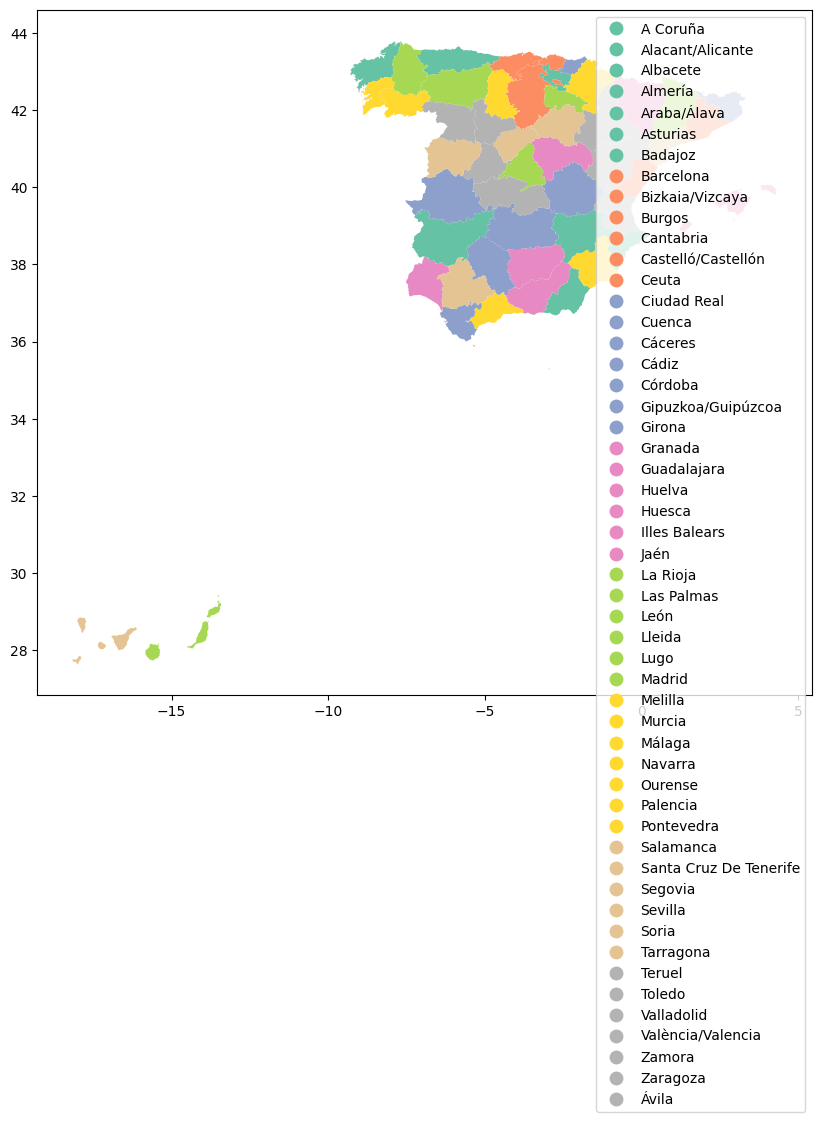

In [45]:
import geopandas as gpd
gdf = gpd.read_file(
    "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-provinces.geojson",
    crs="epsg:4326",
)

gdf.plot(column="name", figsize=(10, 10), legend=True, cmap="Set2")

In [50]:
!pip install contextily

In [106]:
import geopandas as gpd
from shapely.geometry import Point
import contextily as ctx
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Supprimer les lignes sans coordonnées
# Supprimer les lignes sans coordonnées
df_filtered_test = df_filtered.iloc[0:100].dropna(subset=['latitude', 'longitude'])

df_filtered_test['power_mw'] = (
    df_filtered_test['power']
    .str.replace('\xa0', '', regex=False)    # retire l'espace insécable
    .str.replace('MW', '', regex=False)      # retire "MW"
    .str.replace(',', '.', regex=False)      # remplace la virgule par un point
    .str.strip()                             # retire les espaces
    .astype(float)                           # convertit en float
)
# Créer la géométrie
geometry = [Point(xy) for xy in zip(df_filtered_test['longitude'], df_filtered_test['latitude'])]

# Créer un GeoDataFrame
gdf_points = gpd.GeoDataFrame(df_filtered_test, geometry=geometry, crs="EPSG:4326")

# Reprojeter en Web Mercator
gdf_points = gdf_points.to_crs(epsg=3857)

# Créer un colormap basé sur la colonne 'source'
colormap = mpl.cm.get_cmap("viridis", len(df_filtered_test['source'].unique()))

# Créer les tailles de points proportionnelles à 'output'
sizes = gdf_points['power_mw'].fillna(0)
sizes = np.clip(sizes, a_min=1, a_max=None)  # Pour éviter les points invisibles
sizes_scaled = sizes / sizes.max() * 200  # Échelle à ajuster selon le rendu souhaité

# Tracer la carte
fig, ax = plt.subplots(figsize=(10, 10))
gdf_points.plot(
    ax=ax,
    alpha=0.7,
    column='source',
    cmap=colormap,
    markersize=sizes_scaled,
    legend=True
)

# Ajouter le fond de carte
ctx.add_basemap(ax, crs=gdf_points.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

# Ajouter les titres
ax.set_title("Carte des Centrales par Source (taille ∝ output)", fontsize=15)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# Enregistrer en PNG
plt.savefig("carte_centres_coloree.png", format="png", dpi=300, bbox_inches='tight')
plt.close()


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_2856\634396903.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = mpl.cm.get_cmap("viridis", len(df_filtered_test['source'].unique()))


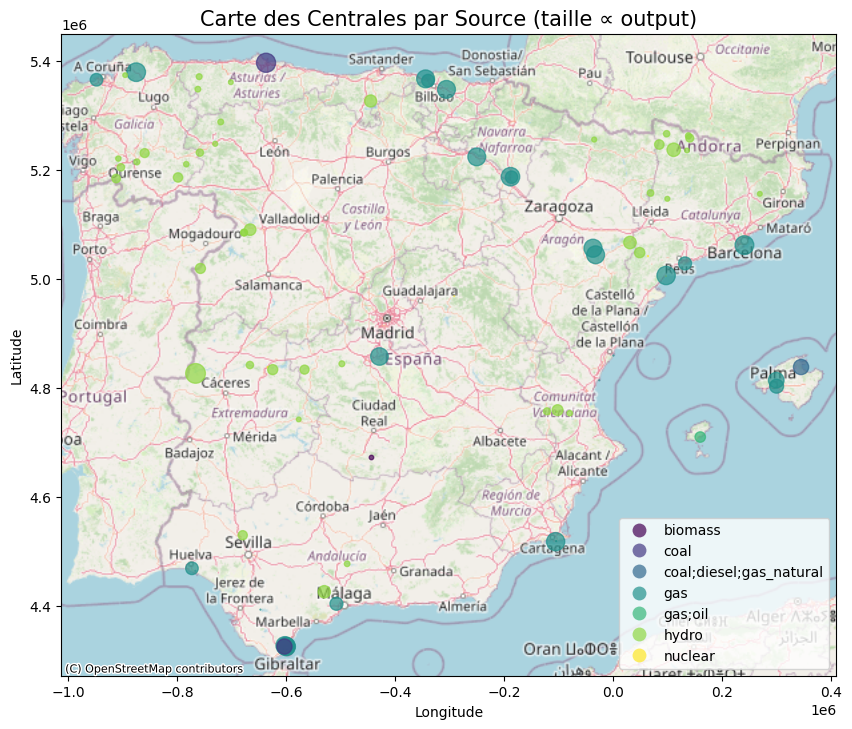

In [108]:

# Calcul des tailles proportionnelles à la colonne 'output'
sizes = gdf_points['power_mw'].fillna(0)
sizes = np.clip(sizes, a_min=1, a_max=None)  # éviter les points invisibles
sizes_scaled = sizes / sizes.max() * 200     # échelle à ajuster

# Tracer la carte
fig, ax = plt.subplots(figsize=(10, 10))
gdf_points.plot(
    ax=ax,
    alpha=0.7,
    markersize=sizes_scaled,
    column='source',
    cmap=colormap,
    legend=True
)

# Ajouter le fond de carte
ctx.add_basemap(ax, crs=gdf_points.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

# Titres
ax.set_title("Carte des Centrales par Source (taille ∝ output)", fontsize=15)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()


In [83]:
import os
#os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
df_filtered = pd.read_csv("plants.csv")
#df_filtered.to_csv("plants.csv", index=False)
fraction_nas = df_filtered['latitude'].isna().mean()
print(f"Fraction of NaNs in 'latitude': {fraction_nas:.2%}")
fraction_nas_wiki = df_filtered['wikidata'].isna().mean()
print(f"Fraction of NaNs in 'wikidata': {fraction_nas:.2%}")
# Créer la colonne geometry à partir des coordonnées (longitude, latitude)
df_filtered = df_filtered.dropna(subset=['latitude', 'longitude'])  # Supprimer les lignes sans coordonnées
print(len(df_filtered))


Fraction of NaNs in 'latitude': 83.41%
Fraction of NaNs in 'wikidata': 83.41%
103
